In [2]:
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
df = pd.read_csv("/home/aio/training/data/diamonds.csv")
df

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [4]:
df.price.min(), df.price.max(), df.price.mean(), df.price.std(), df.price.median()

(np.int64(326),
 np.int64(18823),
 np.float64(3932.799721913237),
 np.float64(3989.439738146379),
 np.float64(2401.0))

ylim (np.float64(0.0), np.float64(5419.05))


Text(2641.1000000000004, 2000, 'Median: 2401.00')

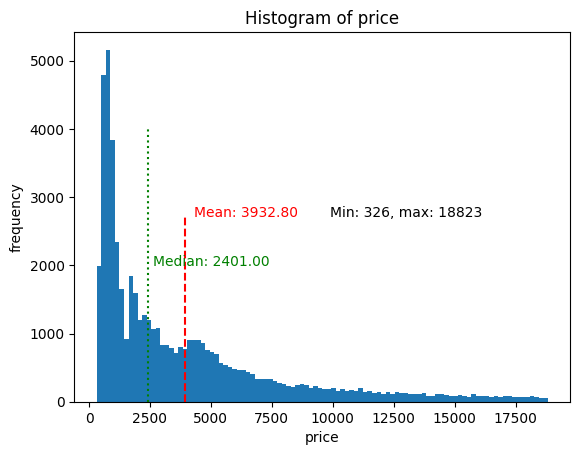

In [27]:
plt.hist(df.price, bins = 100)
plt.title("Histogram of price")
plt.xlabel("price")
plt.ylabel("frequency")

y_min, y_max = plt.ylim()
x_min, x_max = plt.xlim()
print("ylim", plt.ylim())

plt.text(x_max/2, y_max/2, f"Min: {df.price.min()}, max: {df.price.max()}")



plt.vlines(df.price.mean(), 0, y_max/2, color = "red", ls = "--")
plt.text(df.price.mean() * 1.1, y_max/2, f"Mean: {df.price.mean():.2f}", color = "red")


plt.vlines(df.price.median(), 0, 4000, color = "green", ls = ":")
plt.text(df.price.median() * 1.1, 2000, f"Median: {df.price.median():.2f}", color = "green")

{'whiskers': [<matplotlib.lines.Line2D at 0x7f6d2d9801a0>,
 'caps': [<matplotlib.lines.Line2D at 0x7f6d2d981e20>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f6d2d9816d0>],
 'medians': [<matplotlib.lines.Line2D at 0x7f6d2d981e80>],
 'fliers': [<matplotlib.lines.Line2D at 0x7f6d2d9824b0>],
 'means': []}

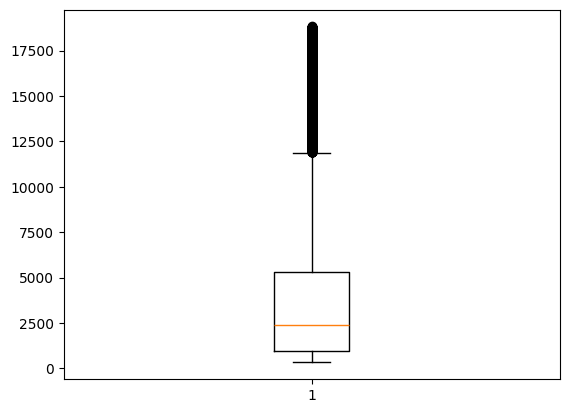

In [29]:
plt.boxplot(df.price)

{'whiskers': [<matplotlib.lines.Line2D at 0x7f6d2c415e80>,
 'caps': [<matplotlib.lines.Line2D at 0x7f6d2c414320>,
 'boxes': [<matplotlib.lines.Line2D at 0x7f6d2c417da0>],
 'medians': [<matplotlib.lines.Line2D at 0x7f6d2c414830>],
 'fliers': [<matplotlib.lines.Line2D at 0x7f6d2c416210>],
 'means': []}

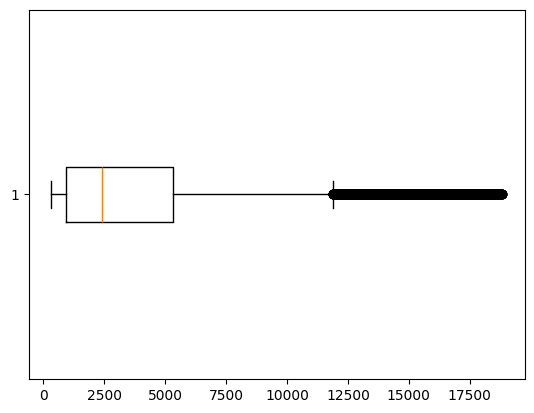

In [41]:
plt.boxplot(df.price, vert = False)

In [31]:
import numpy as np

In [32]:
a = df.price
q1, q2, q3 = np.percentile(a, [25, 50, 75])
iqr = q3 - q1
iqr

np.float64(4374.25)

In [36]:
a = df.price
def find_outliers(a):
    q1, q2, q3 = np.percentile(a, [25, 50, 75])
    iqr = q3 - q1
    upper_whisker = min(a.max(), q3 + 1.5 * iqr)
    lower_whisker = max(a.min(), q1 - 1.5 * iqr)
    print("upper_whisker", upper_whisker)
    return (a > upper_whisker) | (a<lower_whisker)

df[find_outliers(a)]

upper_whisker 11885.625


,carat,cut,color,clarity,depth,table,price,x,y,z
23820,1.17,Ideal,F,VVS1,62.1,57.0,11886,6.82,6.73,4.21
23821,2.08,Ideal,I,SI2,62.0,56.0,11886,8.21,8.10,5.06
23822,1.70,Premium,I,VS2,62.2,58.0,11888,7.65,7.60,4.74
23823,1.09,Ideal,F,IF,61.6,55.0,11888,6.59,6.65,4.08
23824,1.68,Ideal,E,SI2,60.4,55.0,11888,7.79,7.70,4.68
...,...,...,...,...,...,...,...,...,...,...
27745,2.00,Very Good,H,SI1,62.8,57.0,18803,7.95,8.00,5.01
27746,2.07,Ideal,G,SI2,62.5,55.0,18804,8.20,8.13,5.11
27747,1.51,Ideal,G,IF,61.7,55.0,18806,7.37,7.41,4.56
27748,2.00,Very Good,G,SI1,63.5,56.0,18818,7.90,7.97,5.04


ylim (np.float64(0.0), np.float64(5419.05))


Text(2641.1000000000004, 2000, 'Median: 2401.00')

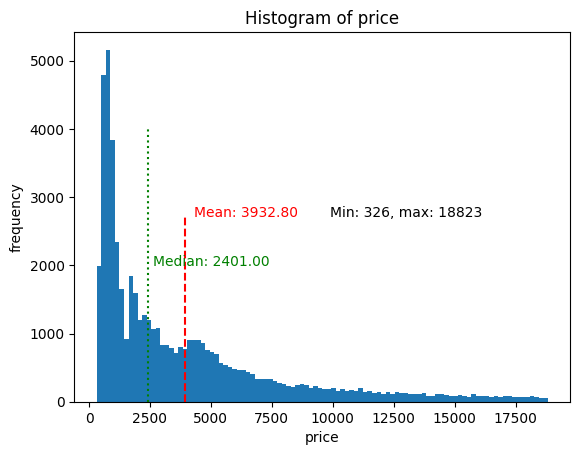